In [1]:
import os
import time
import random
import argparse
import torch
import torchvision
import torchvision.transforms as  transforms

import torch.nn as nn 
import torch.nn.functional as F
import torch.optim as optim
from torch import Tensor
from torch.utils.data import DataLoader
from typing import Type

import matplotlib.pyplot as plt
import numpy as np 


libgomp: Invalid value for environment variable OMP_NUM_THREADS


# Model and Data

In [2]:
#Resnet
class BasicBlock(nn.Module):
    def __init__(
        self, 
        in_channels: int,
        out_channels: int,
        stride: int = 1,
        expansion: int = 1,
        downsample: nn.Module = None
    ) -> None:
        super(BasicBlock, self).__init__()
        # Multiplicative factor for the subsequent conv2d layer's output channels.
        # It is 1 for ResNet18 and ResNet34.
        self.expansion = expansion
        self.downsample = downsample
        self.conv1 = nn.Conv2d(
            in_channels, 
            out_channels, 
            kernel_size=3, 
            stride=stride, 
            padding=1,
            bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(
            out_channels, 
            out_channels*self.expansion, 
            kernel_size=3, 
            padding=1,
            bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels*self.expansion)
    def forward(self, x):
        identity = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        out = self.relu(out)
        return  out


class ResNet(nn.Module):
    def __init__(
        self, 
        img_channels: int,
        num_layers: int,
        block,
        num_classes: int  
    ) -> None:
        super(ResNet, self).__init__()
        if num_layers == 18:
            # The following `layers` list defines the number of `BasicBlock` 
            # to use to build the network and how many basic blocks to stack
            # together.
            layers = [2, 2, 2, 2]
            self.expansion = 1
        elif num_layers == 34:
            layers = [3, 4, 6, 3]
            self.expansion = 1
        elif num_layers == 50:
            layers = [3, 4, 6, 3]
            self.expansion = 4
        elif num_layers == 101:
            layers = [3, 4, 23, 3]
            self.expansion = 4
        
        self.in_channels = 64
        # All ResNets (18 to 152) contain a Conv2d => BN => ReLU for the first
        # three layers. Here, kernel size is 7.
        self.conv1 = nn.Conv2d(
            in_channels=img_channels,
            out_channels=self.in_channels,
            kernel_size=3, 
            stride=1,
            padding=1,
            bias=False
        )
        self.bn1 = nn.BatchNorm2d(self.in_channels)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.Identity()
        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2)
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2)
        self.layer4 = self._make_layer(block, 512, layers[3], stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512*self.expansion, num_classes)
    def _make_layer(
        self, 
        block: Type[BasicBlock],
        out_channels: int,
        blocks: int,
        stride: int = 1
    ) -> nn.Sequential:
        downsample = None
        if stride != 1 or self.in_channels != out_channels * self.expansion:
            """
            This should pass from `layer2` to `layer4` or 
            when building ResNets50 and above. Section 3.3 of the paper
            Deep Residual Learning for Image Recognition
            (https://arxiv.org/pdf/1512.03385v1.pdf).
            """
            downsample = nn.Sequential(
                nn.Conv2d(
                    self.in_channels, 
                    out_channels*self.expansion,
                    kernel_size=1,
                    stride=stride,
                    bias=False 
                ),
                nn.BatchNorm2d(out_channels * self.expansion),
            )
        layers = []
        layers.append(
            block(
                self.in_channels, out_channels, stride, self.expansion, downsample
            )
        )
        self.in_channels = out_channels * self.expansion
        for i in range(1, blocks):
            layers.append(block(
                self.in_channels,
                out_channels,
                expansion=self.expansion
            ))
        return nn.Sequential(*layers)
    def forward(self, x: Tensor) -> Tensor:
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        # The spatial dimension of the final layer's feature 
        # map should be (7, 7) for all ResNets.
        #print('Dimensions of the last convolutional feature map: ', x.shape)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

In [3]:
# ---- 计算设备与可复现性设置 ----
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
# 输入尺寸固定，让 cuDNN 在首次迭代时自动挑选最快的卷积算法
torch.backends.cudnn.benchmark = True

print(f"Device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"torch {torch.__version__}, CUDA {torch.version.cuda}")

Device: cuda
GPU: NVIDIA GeForce RTX 4090
torch 2.14.1+cu126, CUDA 12.6


In [4]:
# data
transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(0.4914, 0.4822, 0.4465),
            std=(0.2470, 0.2435, 0.2616),
        ),
    ])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)

# model
model = ResNet(img_channels=3, num_layers=18, block=BasicBlock, num_classes=10)
model.train()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): Identity()
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(

# Training ResNet-18 on CIFAR-10 below

## 实验 1：SGD 基线（GPU）

本实验建立后续所有优化方法对比所用的基线，设置如下：

| 项目 | 设置 |
| --- | --- |
| 设备 | NVIDIA GeForce RTX 4090（24 GB） |
| 优化器 | SGD |
| 学习率 | 固定 0.1（不做衰减） |
| 动量 | 0.9 |
| 权重衰减 | 0 |
| Batch size | 128 |
| 数据增强 | 无（作业只考察训练集准确率，因此不使用增强） |
| 损失函数 | 交叉熵 |
| 停止条件 | 每个 epoch 结束在训练集上以 `eval` 模式评估，训练准确率首次 ≥ 99% 时停止 |
| 计时方式 | `time.perf_counter()` 计 wall-clock：包含数据加载和每个 epoch 的评估，不含模型构建与数据下载 |

计时口径说明：所有对比实验都使用同一口径，即从第一个 batch 开始训练之前的时刻起算，到评估出训练准确率 ≥ 99% 的那个 epoch 结束为止（该次评估本身也计入耗时，因为不评估就无从得知何时停止）。

In [5]:
# ---- 基线超参数 ----
BATCH_SIZE = 128
LR = 0.1
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0
MAX_EPOCHS = 100
TARGET_TRAIN_ACC = 0.99
NUM_WORKERS = min(8, os.cpu_count() or 1)

# 训练集 DataLoader：训练时打乱顺序
train_loader = DataLoader(
    trainset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
    prefetch_factor=4 if NUM_WORKERS > 0 else None,
)
# 评估同样在训练集上进行；用更大的 batch 降低评估开销
eval_loader = DataLoader(
    trainset,
    batch_size=512,
    shuffle=False,
    num_workers=min(4, NUM_WORKERS),
    pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)


@torch.inference_mode()
def evaluate_train_accuracy(model: nn.Module, loader: DataLoader = None,
                            channels_last: bool = False) -> float:
    """在完整训练集上以 eval 模式（BN 使用 running stats）计算准确率。"""
    loader = eval_loader if loader is None else loader
    model.eval()
    correct = total = 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if channels_last:
            images = images.to(memory_format=torch.channels_last)
        correct += (model(images).argmax(dim=1) == labels).sum().item()
        total += labels.numel()
    return correct / total


def run_sgd_baseline(max_epochs: int = MAX_EPOCHS,
                     target_acc: float = TARGET_TRAIN_ACC) -> dict:
    """训练 ResNet-18，直到训练准确率 >= target_acc 或达到 max_epochs。"""
    set_seed(SEED)
    model = ResNet(img_channels=3, num_layers=18,
                   block=BasicBlock, num_classes=10).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=LR,
                          momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)

    history = {"epoch": [], "train_loss": [], "train_acc": [],
               "epoch_time": [], "cum_time": []}

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    t_start = time.perf_counter()   # 计时起点：第一个 batch 之前
    reached_epoch = None
    reached_time = None

    for epoch in range(1, max_epochs + 1):
        t_epoch = time.perf_counter()
        model.train()
        running_loss = torch.zeros((), device=DEVICE)
        n_seen = 0
        for images, labels in train_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()

            # 在 GPU 上累加损失，避免每个 iteration 同步一次
            running_loss += loss.detach() * labels.size(0)
            n_seen += labels.size(0)

        train_acc = evaluate_train_accuracy(model)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        epoch_time = time.perf_counter() - t_epoch
        cum_time = time.perf_counter() - t_start

        history["epoch"].append(epoch)
        history["train_loss"].append((running_loss / n_seen).item())
        history["train_acc"].append(train_acc)
        history["epoch_time"].append(epoch_time)
        history["cum_time"].append(cum_time)

        print(f"Epoch {epoch:3d} | loss {history['train_loss'][-1]:.4f} "
              f"| train acc {train_acc * 100:6.2f}% "
              f"| epoch {epoch_time:6.2f}s | cumulative {cum_time:7.1f}s")

        if train_acc >= target_acc:
            reached_epoch = epoch
            reached_time = cum_time
            break

    return {
        "model": model,
        "history": history,
        "epochs": len(history["epoch"]),
        "reached_epoch": reached_epoch,
        "time_to_target": reached_time,
        "final_train_acc": history["train_acc"][-1],
        "peak_gpu_mem_gb": (torch.cuda.max_memory_allocated() / 2**30
                            if DEVICE.type == "cuda" else float("nan")),
    }

Epoch   1 | loss 1.9402 | train acc  43.99% | epoch  11.83s | cumulative    11.8s
Epoch   2 | loss 1.4054 | train acc  55.96% | epoch   9.95s | cumulative    21.8s
Epoch   3 | loss 1.1381 | train acc  61.93% | epoch   8.82s | cumulative    30.6s
Epoch   4 | loss 0.9186 | train acc  73.35% | epoch   9.13s | cumulative    39.7s
Epoch   5 | loss 0.7619 | train acc  77.07% | epoch   9.29s | cumulative    49.0s
Epoch   6 | loss 0.6274 | train acc  81.57% | epoch   9.33s | cumulative    58.4s
Epoch   7 | loss 0.5148 | train acc  86.57% | epoch   9.15s | cumulative    67.5s
Epoch   8 | loss 0.4041 | train acc  88.38% | epoch   9.43s | cumulative    76.9s
Epoch   9 | loss 0.3146 | train acc  90.46% | epoch   9.34s | cumulative    86.3s
Epoch  10 | loss 0.2371 | train acc  92.83% | epoch  10.01s | cumulative    96.3s
Epoch  11 | loss 0.1788 | train acc  95.19% | epoch   9.41s | cumulative   105.7s
Epoch  12 | loss 0.1262 | train acc  96.22% | epoch   9.37s | cumulative   115.1s
Epoch  13 | loss

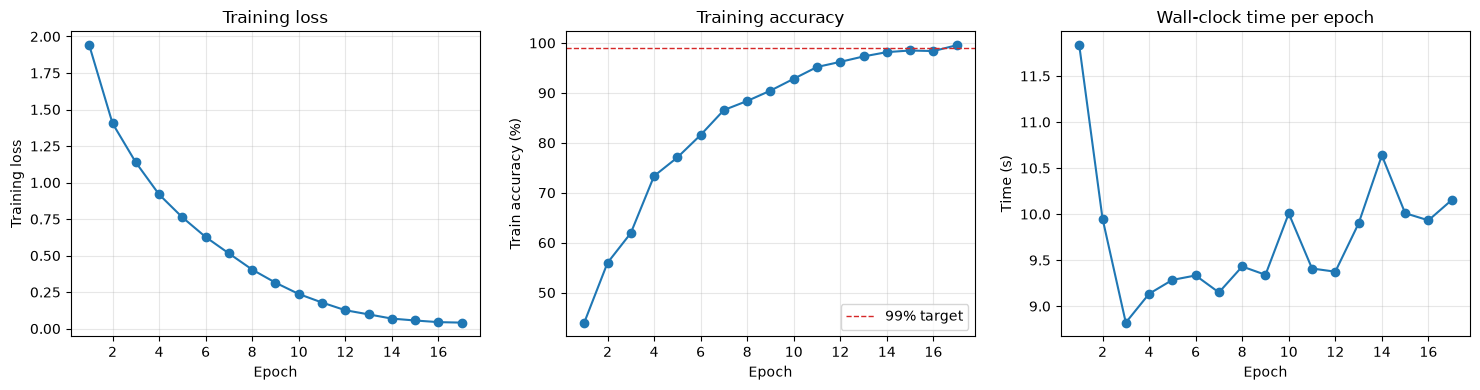

In [6]:
baseline = run_sgd_baseline()
hist = baseline["history"]

print("\n" + "=" * 64)
if baseline["reached_epoch"] is not None:
    print(f"SGD 基线首次达到 {TARGET_TRAIN_ACC * 100:.0f}% 训练准确率："
          f"epoch {baseline['reached_epoch']}，"
          f"耗时 {baseline['time_to_target']:.2f} s")
else:
    print(f"{MAX_EPOCHS} 个 epoch 内未达到 {TARGET_TRAIN_ACC * 100:.0f}% 训练准确率")
print(f"最终训练准确率：{baseline['final_train_acc'] * 100:.2f}%")
print(f"平均每 epoch 耗时：{np.mean(hist['epoch_time']):.2f} s")
print(f"峰值显存占用：{baseline['peak_gpu_mem_gb']:.2f} GB")
print("=" * 64)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(hist["epoch"], hist["train_loss"], marker="o")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training loss")
axes[0].set_title("Training loss")
axes[0].grid(alpha=0.3)

axes[1].plot(hist["epoch"], [a * 100 for a in hist["train_acc"]], marker="o")
axes[1].axhline(TARGET_TRAIN_ACC * 100, color="tab:red", ls="--", lw=1,
                label=f"{TARGET_TRAIN_ACC * 100:.0f}% target")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Train accuracy (%)")
axes[1].set_title("Training accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(hist["epoch"], hist["epoch_time"], marker="o")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Time (s)")
axes[2].set_title("Wall-clock time per epoch")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 实验 2：综合优化版本

在基线之上叠加以下优化（AMP 保持关闭，仍为 fp32）：

| 组件 | 设置 |
| --- | --- |
| 优化器 | SGD + Nesterov 动量 |
| 峰值学习率 | 由 LR range test 确定：在 1e-5 → 0.2 上指数扫描，取平滑后 loss 最低点对应的 lr，上限 0.2 |
| 学习率调度 | one-cycle cosine（总长 5 个 epoch）：前 25%（1.25 个 epoch）为 warmup，lr 从 峰值/25 余弦升至峰值；其余 75% 余弦衰减至 0.001；超出 5 个 epoch 后保持 0.001 |
| Momentum 调度 | one-cycle cosine：warmup 期间 0.95 → 0.85 余弦下降，随后余弦升回 0.95；超出 5 个 epoch 后保持 0.95 |
| channels_last | 开启（模型参数与输入张量） |
| torch.compile | 开启；编译预热在计时外完成 |
| AMP | 关闭 |
| 停止条件 | 训练准确率 ≥ 99% 或达到 `MAX_EPOCHS`（100） |

说明：学习率与动量调度参照 HW4 的 aggressive 版本（one-cycle cosine，`pct_start=0.25`、`div_factor=25`、`min_lr=0.001`、momentum 0.95 ↔ 0.85），按 iteration 插值，并与 `torch.optim.lr_scheduler.OneCycleLR`（`anneal_strategy="cos"`、`three_phase=False`）逐 step 校验一致。优化器使用 Nesterov 动量；LR range test、调度校验与正式训练采用同一 Nesterov 设置。LR range test 与 compile 预热都属于一次性实验设置，不计入训练耗时；正式计时口径与基线一致（第一个 batch 之前起算，到首次评估出 ≥ 99% 的 epoch 结束，含每 epoch 的评估和数据加载）。为了让 `torch.compile` 不因形状变化重复编译，本实验的训练集 DataLoader 使用 `drop_last=True`（每个 epoch 49920 张），评估 batch 取 500（50000 可整除）。

In [7]:
# ---- 实验 2 设置 ----
PEAK_LR_CAP = 0.2            # LR range test 的扫描上限
CYCLE_EPOCHS = 5             # one-cycle 总轮数（5 个 epoch 完成整个调度）
PCT_START = 0.25             # warmup 占总步数的比例（5 个 epoch 中前 1.25 个）
DIV_FACTOR = 25.0            # warmup 起点 lr = 峰值 lr / DIV_FACTOR
MIN_LR = 0.001               # cosine 衰减终点的 lr
MOMENTUM_HIGH = 0.95         # warmup 起点 / 衰减终点的 momentum
MOMENTUM_LOW = 0.85          # warmup 终点 / 衰减起点的 momentum
USE_NESTEROV = True          # Nesterov 动量（LR range test、调度校验与训练一致）
USE_CHANNELS_LAST = True
USE_COMPILE = True           # 采用 torch.compile，编译预热在计时外完成
USE_AMP = False              # 按实验要求关闭 AMP，全程 fp32

LR range test 选定峰值学习率：0.03018（上限 0.2）—— 取平滑后 loss 最低点对应的 lr


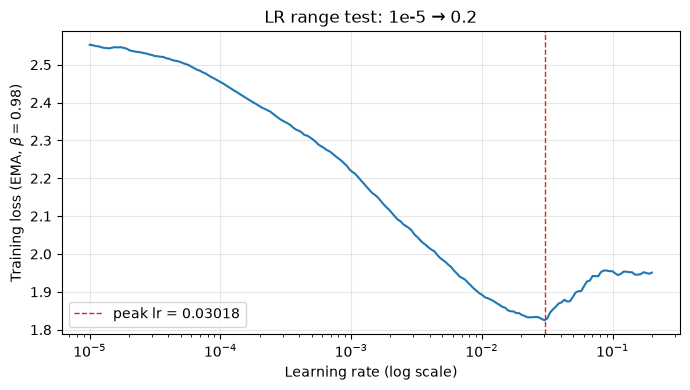

In [8]:
# ---- LR range test：在 [1e-5, 0.2] 上指数扫描学习率 ----
def lr_range_test(start_lr: float = 1e-5,
                  end_lr: float = PEAK_LR_CAP,
                  num_iter: int = 200,
                  ema_beta: float = 0.98) -> dict:
    """指数扫描 lr，返回平滑 loss 最低点对应的 lr（即峰值 lr，上限 end_lr）。"""
    set_seed(SEED)
    model = ResNet(img_channels=3, num_layers=18,
                   block=BasicBlock, num_classes=10).to(DEVICE)
    if USE_CHANNELS_LAST:
        model = model.to(memory_format=torch.channels_last)
    model.train()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=start_lr,
                          momentum=MOMENTUM_HIGH, nesterov=USE_NESTEROV)

    probe_loader = DataLoader(
        trainset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
        num_workers=NUM_WORKERS, pin_memory=True,
        persistent_workers=NUM_WORKERS > 0,
        prefetch_factor=4 if NUM_WORKERS > 0 else None,
    )

    lrs, losses = [], []
    ema = None
    for i, (images, labels) in enumerate(probe_loader):
        if i >= num_iter:
            break
        lr = start_lr * (end_lr / start_lr) ** (i / (num_iter - 1))
        for group in optimizer.param_groups:
            group["lr"] = lr

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if USE_CHANNELS_LAST:
            images = images.to(memory_format=torch.channels_last)

        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()

        value = loss.item()
        if not np.isfinite(value):
            print(f"LR range test：第 {i} 次迭代 loss 发散，提前结束扫描")
            break
        ema = value if ema is None else ema_beta * ema + (1 - ema_beta) * value
        lrs.append(lr)
        losses.append(ema)

    del model, optimizer, probe_loader
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    best = int(np.argmin(losses))
    if best < 5:  # 曲线没有下降（例如初始化异常），使用保守值
        peak_lr = min(0.1, end_lr)
        note = "平滑 loss 未出现明显下降，回退到 0.1"
    else:
        peak_lr = float(lrs[best])
        note = "取平滑后 loss 最低点对应的 lr"
    return {"peak_lr": peak_lr, "lrs": lrs, "losses": losses,
            "best_index": best, "note": note}


lr_result = lr_range_test()
PEAK_LR = lr_result["peak_lr"]
print(f"LR range test 选定峰值学习率：{PEAK_LR:.4g}"
      f"（上限 {PEAK_LR_CAP}）—— {lr_result['note']}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lr_result["lrs"], lr_result["losses"], lw=1.5)
ax.axvline(PEAK_LR, color="tab:red", ls="--", lw=1,
           label=f"peak lr = {PEAK_LR:.4g}")
ax.set_xscale("log")
ax.set_xlabel("Learning rate (log scale)")
ax.set_ylabel(r"Training loss (EMA, $\beta=0.98$)")
ax.set_title("LR range test: 1e-5 → 0.2")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

one-cycle 调度校验通过：max lr error=0.000e+00，max momentum error=0.000e+00
one-cycle cosine：5 epochs × 390 iters = 1950 steps | warmup 25% | lr 0.001207 → 0.03018 → 0.001 | momentum 0.95 → 0.85 → 0.95 | nesterov True
Epoch   1 | lr 0.0274 | mom 0.860 | loss 1.3071 | train acc  68.19% | epoch   9.63s | cumulative     9.6s
Epoch   2 | lr 0.0274 | mom 0.860 | loss 0.7264 | train acc  79.13% | epoch   9.60s | cumulative    19.2s
Epoch   3 | lr 0.0171 | mom 0.895 | loss 0.4784 | train acc  88.06% | epoch   9.00s | cumulative    28.2s
Epoch   4 | lr 0.0058 | mom 0.933 | loss 0.2775 | train acc  94.86% | epoch   9.33s | cumulative    37.6s
Epoch   5 | lr 0.0010 | mom 0.950 | loss 0.0815 | train acc  99.68% | epoch   9.24s | cumulative    46.8s

LR range test 峰值学习率：0.03018（上限 0.2）
one-cycle cosine：5 epochs，warmup 25%（lr 0.001207 → 0.03018 → 0.001；momentum 0.95 → 0.85 → 0.95）
torch.compile：开启（编译预热在计时外）
AMP：关闭（全程 fp32）
Nesterov：开启
channels_last：开启
首次达到 99% 训练准确率：epoch 5，耗时 46.79 s
最终训练准确率：99.68%
平均每 e

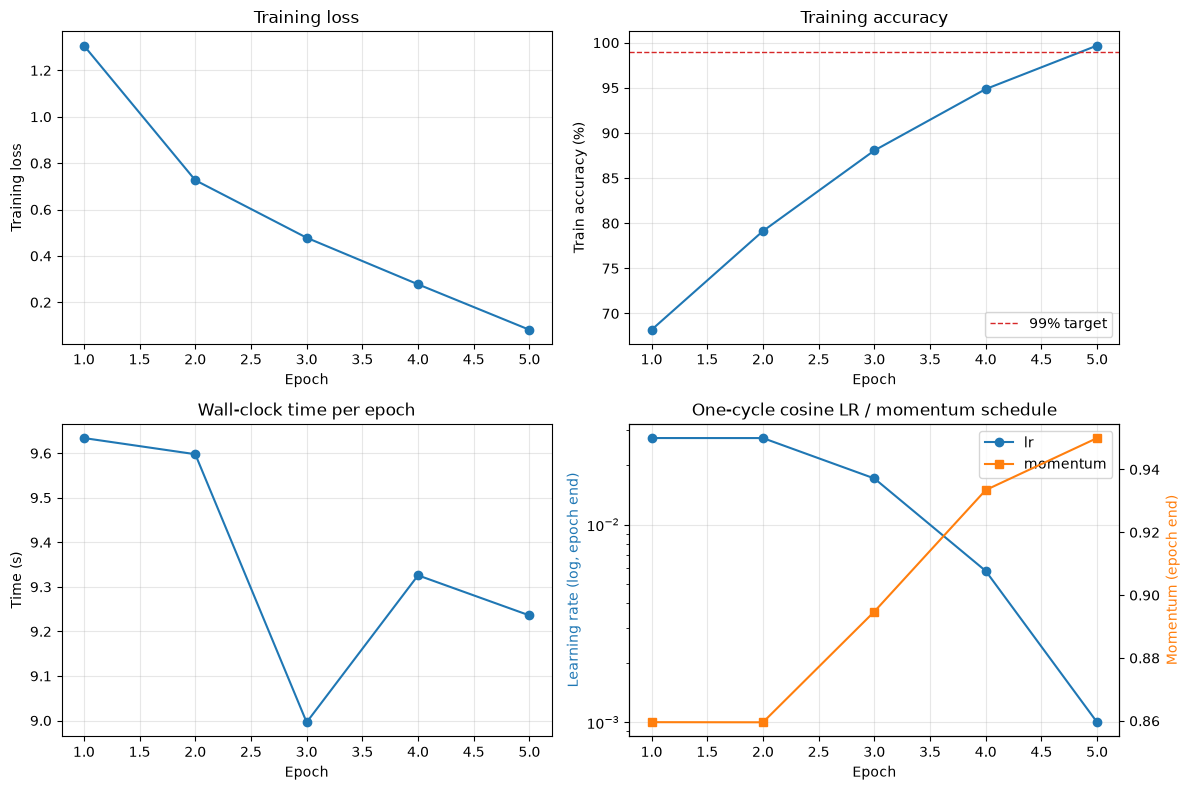

In [9]:
import math


def _cos_anneal(start: float, end: float, pct: float) -> float:
    """OneCycleLR 使用的 cosine 插值。"""
    pct = min(max(pct, 0.0), 1.0)
    return end + (start - end) / 2.0 * (math.cos(math.pi * pct) + 1.0)


def make_one_cycle_schedule(total_steps: int, peak_lr: float):
    """构造 one-cycle cosine 学习率与动量调度（逐 iteration 调用）。

    前 PCT_START 的步数为 cosine warmup：lr 从 峰值/DIV_FACTOR 升到峰值，
    momentum 从 MOMENTUM_HIGH 降到 MOMENTUM_LOW；其余步数为 cosine 衰减：
    lr 从峰值降到 MIN_LR，momentum 从 MOMENTUM_LOW 升回 MOMENTUM_HIGH。
    超出 total_steps 后钳在各自终值（min lr / 最大 momentum），可继续训练。
    """
    warmup_end = PCT_START * total_steps - 1
    initial_lr = peak_lr / DIV_FACTOR
    anneal_steps = (total_steps - 1) - warmup_end

    def lr_at(it: int) -> float:
        if it <= warmup_end:
            return _cos_anneal(initial_lr, peak_lr, it / warmup_end)
        return _cos_anneal(peak_lr, MIN_LR, (it - warmup_end) / anneal_steps)

    def momentum_at(it: int) -> float:
        if it <= warmup_end:
            return _cos_anneal(MOMENTUM_HIGH, MOMENTUM_LOW,
                               it / warmup_end)
        return _cos_anneal(MOMENTUM_LOW, MOMENTUM_HIGH,
                           (it - warmup_end) / anneal_steps)

    return lr_at, momentum_at


def verify_one_cycle_schedule(total_steps: int, peak_lr: float) -> None:
    """与 torch.optim.lr_scheduler.OneCycleLR 逐 step 校验调度一致性。"""
    import warnings
    warnings.filterwarnings(
        "ignore",
        message=r".*lr_scheduler\.step.*before.*optimizer\.step.*",
        category=UserWarning,
    )  # 校验过程不调用 optimizer.step()
    lr_at, momentum_at = make_one_cycle_schedule(total_steps, peak_lr)
    probe_param = torch.nn.Parameter(torch.zeros(1))
    probe_opt = optim.SGD([probe_param], lr=peak_lr, momentum=MOMENTUM_HIGH,
                          nesterov=USE_NESTEROV)
    ref = optim.lr_scheduler.OneCycleLR(
        probe_opt,
        max_lr=peak_lr,
        total_steps=total_steps,
        pct_start=PCT_START,
        anneal_strategy="cos",
        cycle_momentum=True,
        base_momentum=MOMENTUM_LOW,
        max_momentum=MOMENTUM_HIGH,
        div_factor=DIV_FACTOR,
        final_div_factor=(peak_lr / DIV_FACTOR) / MIN_LR,
        three_phase=False,
    )
    max_lr_err = max_mom_err = 0.0
    for step in range(total_steps):
        if step > 0:
            ref.step()
        group = probe_opt.param_groups[0]
        max_lr_err = max(max_lr_err, abs(group["lr"] - lr_at(step)))
        max_mom_err = max(max_mom_err,
                          abs(group["momentum"] - momentum_at(step)))
    assert max_lr_err < 1e-9, max_lr_err
    assert max_mom_err < 1e-12, max_mom_err
    print(f"one-cycle 调度校验通过：max lr error={max_lr_err:.3e}，"
          f"max momentum error={max_mom_err:.3e}")


def run_optimized(peak_lr: float,
                  max_epochs: int = MAX_EPOCHS,
                  target_acc: float = TARGET_TRAIN_ACC) -> dict:
    """实验 2：peak lr + one-cycle cosine 调度 + Nesterov + channels_last + compile。"""
    set_seed(SEED)

    model = ResNet(img_channels=3, num_layers=18,
                   block=BasicBlock, num_classes=10).to(DEVICE)
    if USE_CHANNELS_LAST:
        model = model.to(memory_format=torch.channels_last)
    if USE_COMPILE:
        model = torch.compile(model)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=1e-3, momentum=MOMENTUM_HIGH,
                          nesterov=USE_NESTEROV)

    opt_train_loader = DataLoader(
        trainset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
        num_workers=NUM_WORKERS, pin_memory=True,
        persistent_workers=NUM_WORKERS > 0,
        prefetch_factor=4 if NUM_WORKERS > 0 else None,
    )
    # 50000 能被 500 整除：固定评估 shape，避免 compile 每次因最后一个小 batch 重编译
    opt_eval_loader = DataLoader(
        trainset, batch_size=500, shuffle=False,
        num_workers=min(4, NUM_WORKERS), pin_memory=True,
        persistent_workers=NUM_WORKERS > 0,
    )

    # one-cycle 调度：drop_last 后每个 epoch 390 步，总步数 = 5 × 390
    iters_per_epoch = len(opt_train_loader)
    total_steps = CYCLE_EPOCHS * iters_per_epoch
    lr_at, momentum_at = make_one_cycle_schedule(total_steps, peak_lr)
    verify_one_cycle_schedule(total_steps, peak_lr)
    print(f"one-cycle cosine：{CYCLE_EPOCHS} epochs × {iters_per_epoch} iters "
          f"= {total_steps} steps | warmup {PCT_START:.0%} | "
          f"lr {peak_lr / DIV_FACTOR:.4g} → {peak_lr:.4g} → {MIN_LR:g} | "
          f"momentum {MOMENTUM_HIGH:.2f} → {MOMENTUM_LOW:.2f} → "
          f"{MOMENTUM_HIGH:.2f} | nesterov {USE_NESTEROV}")

    # compile 预热：用固定形状的随机 batch 触发编译，编译时间不计入训练耗时
    if USE_COMPILE:
        warm_optimizer = optim.SGD(model.parameters(), lr=0.0,
                                   momentum=MOMENTUM_HIGH,
                                   nesterov=USE_NESTEROV)
        model.train()
        for _ in range(2):
            xw = torch.randn(BATCH_SIZE, 3, 32, 32, device=DEVICE)
            yw = torch.randint(0, 10, (BATCH_SIZE,), device=DEVICE)
            if USE_CHANNELS_LAST:
                xw = xw.to(memory_format=torch.channels_last)
            warm_optimizer.zero_grad(set_to_none=True)
            criterion(model(xw), yw).backward()
            warm_optimizer.step()

        model.eval()
        with torch.inference_mode():
            xe = torch.randn(500, 3, 32, 32, device=DEVICE)
            if USE_CHANNELS_LAST:
                xe = xe.to(memory_format=torch.channels_last)
            model(xe)
        model.train()

        del warm_optimizer
        optimizer.zero_grad(set_to_none=True)
        # 预热用的随机 batch 会污染 BN 的 running stats，恢复到初始状态
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.reset_running_stats()

    history = {"epoch": [], "train_loss": [], "train_acc": [],
               "epoch_time": [], "cum_time": [], "lr": [], "momentum": []}

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    t_start = time.perf_counter()   # 计时起点：第一个 batch 之前
    global_it = 0
    reached_epoch = None
    reached_time = None

    for epoch in range(1, max_epochs + 1):
        t_epoch = time.perf_counter()
        model.train()
        running_loss = torch.zeros((), device=DEVICE)
        n_seen = 0
        last_lr = last_momentum = None

        for images, labels in opt_train_loader:
            last_lr = lr_at(global_it)
            last_momentum = momentum_at(global_it)
            for group in optimizer.param_groups:
                group["lr"] = last_lr
                group["momentum"] = last_momentum

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            if USE_CHANNELS_LAST:
                images = images.to(memory_format=torch.channels_last)

            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.detach() * labels.size(0)
            n_seen += labels.size(0)
            global_it += 1

        train_acc = evaluate_train_accuracy(model, opt_eval_loader,
                                            USE_CHANNELS_LAST)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        epoch_time = time.perf_counter() - t_epoch
        cum_time = time.perf_counter() - t_start

        history["epoch"].append(epoch)
        history["train_loss"].append((running_loss / n_seen).item())
        history["train_acc"].append(train_acc)
        history["epoch_time"].append(epoch_time)
        history["cum_time"].append(cum_time)
        history["lr"].append(last_lr)
        history["momentum"].append(last_momentum)

        print(f"Epoch {epoch:3d} | lr {last_lr:.4f} | mom {last_momentum:.3f} "
              f"| loss {history['train_loss'][-1]:.4f} "
              f"| train acc {train_acc * 100:6.2f}% "
              f"| epoch {epoch_time:6.2f}s | cumulative {cum_time:7.1f}s")

        if train_acc >= target_acc:
            reached_epoch = epoch
            reached_time = cum_time
            break

    return {
        "model": model,
        "history": history,
        "epochs": len(history["epoch"]),
        "reached_epoch": reached_epoch,
        "time_to_target": reached_time,
        "final_train_acc": history["train_acc"][-1],
        "peak_gpu_mem_gb": (torch.cuda.max_memory_allocated() / 2**30
                            if DEVICE.type == "cuda" else float("nan")),
    }


opt_result = run_optimized(PEAK_LR)
hist = opt_result["history"]

print("\n" + "=" * 64)
print(f"LR range test 峰值学习率：{PEAK_LR:.4g}（上限 {PEAK_LR_CAP}）")
print(f"one-cycle cosine：{CYCLE_EPOCHS} epochs，warmup {PCT_START:.0%}"
      f"（lr {PEAK_LR / DIV_FACTOR:.4g} → {PEAK_LR:.4g} → {MIN_LR:g}；"
      f"momentum {MOMENTUM_HIGH:.2f} → {MOMENTUM_LOW:.2f} → "
      f"{MOMENTUM_HIGH:.2f}）")
print(f"torch.compile：{'开启' if USE_COMPILE else '关闭'}（编译预热在计时外）")
print("AMP：关闭（全程 fp32）")
print(f"Nesterov：{'开启' if USE_NESTEROV else '关闭'}")
print(f"channels_last：{'开启' if USE_CHANNELS_LAST else '关闭'}")
if opt_result["reached_epoch"] is not None:
    print(f"首次达到 {TARGET_TRAIN_ACC * 100:.0f}% 训练准确率："
          f"epoch {opt_result['reached_epoch']}，"
          f"耗时 {opt_result['time_to_target']:.2f} s")
else:
    print(f"{MAX_EPOCHS} 个 epoch 内未达到 {TARGET_TRAIN_ACC * 100:.0f}% 训练准确率")
print(f"最终训练准确率：{opt_result['final_train_acc'] * 100:.2f}%")
print(f"平均每 epoch 耗时：{np.mean(hist['epoch_time']):.2f} s")
print(f"峰值显存占用：{opt_result['peak_gpu_mem_gb']:.2f} GB")
if ("baseline" in globals() and baseline.get("time_to_target")
        and opt_result["time_to_target"]):
    speedup = baseline["time_to_target"] / opt_result["time_to_target"]
    print(f"相对 SGD 基线加速比：{speedup:.2f}x")
print("=" * 64)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(hist["epoch"], hist["train_loss"], marker="o")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Training loss")
axes[0, 0].set_title("Training loss")
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(hist["epoch"], [a * 100 for a in hist["train_acc"]], marker="o")
axes[0, 1].axhline(TARGET_TRAIN_ACC * 100, color="tab:red", ls="--", lw=1,
                   label=f"{TARGET_TRAIN_ACC * 100:.0f}% target")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Train accuracy (%)")
axes[0, 1].set_title("Training accuracy")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(hist["epoch"], hist["epoch_time"], marker="o")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Time (s)")
axes[1, 0].set_title("Wall-clock time per epoch")
axes[1, 0].grid(alpha=0.3)

ax_lr = axes[1, 1]
ax_lr.plot(hist["epoch"], hist["lr"], color="tab:blue", marker="o", label="lr")
ax_lr.set_yscale("log")
ax_lr.set_xlabel("Epoch")
ax_lr.set_ylabel("Learning rate (log, epoch end)", color="tab:blue")
ax_lr.set_title("One-cycle cosine LR / momentum schedule")
ax_lr.grid(alpha=0.3)
ax_mom = ax_lr.twinx()
ax_mom.plot(hist["epoch"], hist["momentum"], color="tab:orange",
            marker="s", label="momentum")
ax_mom.set_ylabel("Momentum (epoch end)", color="tab:orange")
lines_lr, labels_lr = ax_lr.get_legend_handles_labels()
lines_mom, labels_mom = ax_mom.get_legend_handles_labels()
ax_lr.legend(lines_lr + lines_mom, labels_lr + labels_mom, loc="best")

plt.tight_layout()
plt.show()

Nesterov-only：lr=0.1，momentum=0.9，nesterov=True，epoch 上限 30
Epoch   1 | loss 1.7037 | train acc  52.63% | epoch  10.52s | cumulative    10.5s
Epoch   2 | loss 1.1608 | train acc  63.02% | epoch  10.44s | cumulative    21.0s
Epoch   3 | loss 0.9007 | train acc  72.96% | epoch  10.56s | cumulative    31.5s
Epoch   4 | loss 0.7276 | train acc  80.29% | epoch  10.97s | cumulative    42.5s
Epoch   5 | loss 0.5947 | train acc  82.24% | epoch  10.94s | cumulative    53.4s
Epoch   6 | loss 0.4846 | train acc  86.82% | epoch  10.83s | cumulative    64.3s
Epoch   7 | loss 0.3821 | train acc  90.66% | epoch  10.94s | cumulative    75.2s
Epoch   8 | loss 0.2903 | train acc  93.06% | epoch  11.25s | cumulative    86.5s
Epoch   9 | loss 0.2172 | train acc  94.51% | epoch  10.79s | cumulative    97.3s
Epoch  10 | loss 0.1590 | train acc  96.20% | epoch  10.93s | cumulative   108.2s
Epoch  11 | loss 0.1218 | train acc  96.80% | epoch  10.73s | cumulative   118.9s
Epoch  12 | loss 0.0956 | train acc  9

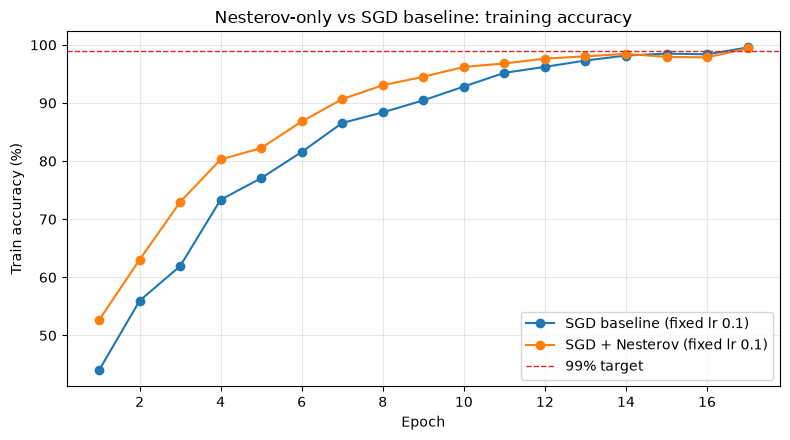

In [10]:
# ---- 对照实验 1：Nesterov-only（基线 + Nesterov，固定 lr 0.1）----
# 运行前请先运行实验 1 的基线 cell（至少运行到定义 train_loader、
# evaluate_train_accuracy 的 cell）。如果 baseline 变量不存在，本 cell 仍可
# 单独得到 Nesterov-only 结果，只是不做基线对比。
# 上限 30 个 epoch：基线在 epoch 16 达标，30 个 epoch 足以判断 Nesterov
# 是否比基线更优；避免无收益的长跑。
NESTEROV_MAX_EPOCHS = 30


def run_sgd_nesterov(max_epochs: int = NESTEROV_MAX_EPOCHS,
                     target_acc: float = TARGET_TRAIN_ACC) -> dict:
    """与 run_sgd_baseline 相同的设置，只把 momentum 更新换成 Nesterov。"""
    set_seed(SEED)
    model = ResNet(img_channels=3, num_layers=18,
                   block=BasicBlock, num_classes=10).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=LR,
                          momentum=MOMENTUM, weight_decay=WEIGHT_DECAY,
                          nesterov=True)

    history = {"epoch": [], "train_loss": [], "train_acc": [],
               "epoch_time": [], "cum_time": []}

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    t_start = time.perf_counter()   # 计时起点：第一个 batch 之前
    reached_epoch = None
    reached_time = None

    for epoch in range(1, max_epochs + 1):
        t_epoch = time.perf_counter()
        model.train()
        running_loss = torch.zeros((), device=DEVICE)
        n_seen = 0
        for images, labels in train_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.detach() * labels.size(0)
            n_seen += labels.size(0)

        train_acc = evaluate_train_accuracy(model)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        epoch_time = time.perf_counter() - t_epoch
        cum_time = time.perf_counter() - t_start

        history["epoch"].append(epoch)
        history["train_loss"].append((running_loss / n_seen).item())
        history["train_acc"].append(train_acc)
        history["epoch_time"].append(epoch_time)
        history["cum_time"].append(cum_time)

        print(f"Epoch {epoch:3d} | loss {history['train_loss'][-1]:.4f} "
              f"| train acc {train_acc * 100:6.2f}% "
              f"| epoch {epoch_time:6.2f}s | cumulative {cum_time:7.1f}s")

        if train_acc >= target_acc:
            reached_epoch = epoch
            reached_time = cum_time
            break

    return {
        "model": model,
        "history": history,
        "epochs": len(history["epoch"]),
        "reached_epoch": reached_epoch,
        "time_to_target": reached_time,
        "final_train_acc": history["train_acc"][-1],
        "peak_gpu_mem_gb": (torch.cuda.max_memory_allocated() / 2**30
                            if DEVICE.type == "cuda" else float("nan")),
    }


print(f"Nesterov-only：lr={LR}，momentum={MOMENTUM}，nesterov=True，"
      f"epoch 上限 {NESTEROV_MAX_EPOCHS}")
nesterov_result = run_sgd_nesterov()
nesterov_hist = nesterov_result["history"]

print("\n" + "=" * 64)
if nesterov_result["reached_epoch"] is not None:
    print(f"Nesterov-only 首次达到 {TARGET_TRAIN_ACC * 100:.0f}% 训练准确率："
          f"epoch {nesterov_result['reached_epoch']}，"
          f"耗时 {nesterov_result['time_to_target']:.2f} s")
else:
    print(f"{NESTEROV_MAX_EPOCHS} 个 epoch 内未达到 {TARGET_TRAIN_ACC * 100:.0f}% 训练准确率")
print(f"最终训练准确率：{nesterov_result['final_train_acc'] * 100:.2f}%")
print(f"平均每 epoch 耗时：{np.mean(nesterov_hist['epoch_time']):.2f} s")
print(f"峰值显存占用：{nesterov_result['peak_gpu_mem_gb']:.2f} GB")
if "baseline" in globals() and baseline.get("time_to_target") and nesterov_result["time_to_target"]:
    print(f"相对 SGD 基线加速比：{baseline['time_to_target'] / nesterov_result['time_to_target']:.2f}x")
else:
    print("未找到 baseline 结果或未达标，跳过加速比；如需对比请先运行实验 1 基线 cell。")
print("=" * 64)

fig, ax = plt.subplots(figsize=(8, 4.5))
if "baseline" in globals():
    base_hist = baseline["history"]
    ax.plot(base_hist["epoch"], [a * 100 for a in base_hist["train_acc"]],
            marker="o", label="SGD baseline (fixed lr 0.1)")
ax.plot(nesterov_hist["epoch"], [a * 100 for a in nesterov_hist["train_acc"]],
        marker="o", label="SGD + Nesterov (fixed lr 0.1)")
ax.axhline(TARGET_TRAIN_ACC * 100, color="tab:red", ls="--", lw=1,
           label=f"{TARGET_TRAIN_ACC * 100:.0f}% target")
ax.set_xlabel("Epoch")
ax.set_ylabel("Train accuracy (%)")
ax.set_title("Nesterov-only vs SGD baseline: training accuracy")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


one-cycle 调度校验通过：max lr error=0.000e+00，max momentum error=0.000e+00
one-cycle cosine：10 epochs × 390 iters = 3900 steps | warmup 25% | lr 0.001207 → 0.03018 → 0.001 | momentum 0.95 → 0.85 → 0.95 | nesterov True
Epoch   1 | lr 0.0112 | mom 0.916 | loss 1.3292 | train acc  67.68% | epoch   9.54s | cumulative     9.5s
Epoch   2 | lr 0.0274 | mom 0.860 | loss 0.7766 | train acc  76.23% | epoch   9.16s | cumulative    18.7s
Epoch   3 | lr 0.0299 | mom 0.851 | loss 0.5453 | train acc  82.66% | epoch   8.28s | cumulative    27.0s
Epoch   4 | lr 0.0274 | mom 0.860 | loss 0.3826 | train acc  91.09% | epoch   9.02s | cumulative    36.0s
Epoch   5 | lr 0.0229 | mom 0.875 | loss 0.2548 | train acc  93.80% | epoch   9.04s | cumulative    45.0s
Epoch   6 | lr 0.0171 | mom 0.895 | loss 0.1508 | train acc  96.17% | epoch   9.24s | cumulative    54.3s
Epoch   7 | lr 0.0111 | mom 0.915 | loss 0.0663 | train acc  98.75% | epoch   9.23s | cumulative    63.5s
Epoch   8 | lr 0.0058 | mom 0.933 | loss 0.020

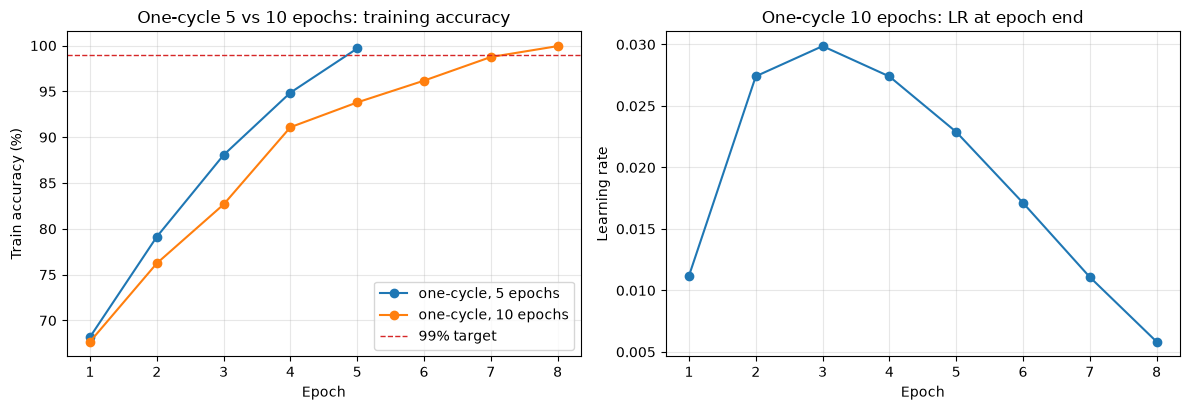

In [11]:
# ---- 对照实验 2：one-cycle 10 epochs（只改周期长度）----
# 复用实验 2 的 run_optimized 与 PEAK_LR，只把 CYCLE_EPOCHS 从 5 改为 10；
# 其余超参数、模型、数据、评测与计时口径完全一致。
# 运行前请先运行实验 2 的 cell（其中定义了 run_optimized；该 cell 也会得到
# 5-epoch 结果）。如果只想跑本 cell，请先至少运行到定义 run_optimized 的 cell。
# 上限 30 个 epoch：5-epoch 方案在 epoch 5 达标，若 10-epoch 调度到 30 个
# epoch 仍未达标，则已可判定它不优于 5-epoch。
CONTROL_MAX_EPOCHS = 30

if "run_optimized" not in globals():
    raise RuntimeError(
        "run_optimized 尚未定义：请先运行实验 2 的 cell（或从顶部 Run All 到本 cell）。"
    )

_cycle_epochs_backup = CYCLE_EPOCHS
try:
    CYCLE_EPOCHS = 10
    onecycle10_result = run_optimized(PEAK_LR, max_epochs=CONTROL_MAX_EPOCHS)
finally:
    CYCLE_EPOCHS = _cycle_epochs_backup

onecycle10_hist = onecycle10_result["history"]

print("\n" + "=" * 64)
print(f"one-cycle 10 epochs（peak lr {PEAK_LR:.4g}，epoch 上限 {CONTROL_MAX_EPOCHS}）")
if onecycle10_result["reached_epoch"] is not None:
    print(f"首次达到 {TARGET_TRAIN_ACC * 100:.0f}% 训练准确率："
          f"epoch {onecycle10_result['reached_epoch']}，"
          f"耗时 {onecycle10_result['time_to_target']:.2f} s")
else:
    print(f"{CONTROL_MAX_EPOCHS} 个 epoch 内未达到 {TARGET_TRAIN_ACC * 100:.0f}% 训练准确率")
print(f"最终训练准确率：{onecycle10_result['final_train_acc'] * 100:.2f}%")
print(f"平均每 epoch 耗时：{np.mean(onecycle10_hist['epoch_time']):.2f} s")
print(f"峰值显存占用：{onecycle10_result['peak_gpu_mem_gb']:.2f} GB")
if "baseline" in globals() and baseline.get("time_to_target") and onecycle10_result["time_to_target"]:
    print(f"相对 SGD 基线加速比：{baseline['time_to_target'] / onecycle10_result['time_to_target']:.2f}x")
if "opt_result" in globals() and opt_result.get("time_to_target") and onecycle10_result["time_to_target"]:
    print(f"相对 5-epoch one-cycle 加速比：{opt_result['time_to_target'] / onecycle10_result['time_to_target']:.2f}x")
print("=" * 64)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

if "opt_result" in globals():
    h5 = opt_result["history"]
    axes[0].plot(h5["epoch"], [a * 100 for a in h5["train_acc"]],
                 marker="o", label="one-cycle, 5 epochs")
axes[0].plot(onecycle10_hist["epoch"],
             [a * 100 for a in onecycle10_hist["train_acc"]],
             marker="o", label="one-cycle, 10 epochs")
axes[0].axhline(TARGET_TRAIN_ACC * 100, color="tab:red", ls="--", lw=1,
                label=f"{TARGET_TRAIN_ACC * 100:.0f}% target")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Train accuracy (%)")
axes[0].set_title("One-cycle 5 vs 10 epochs: training accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(onecycle10_hist["epoch"], onecycle10_hist["lr"],
             marker="o", label="lr (epoch end)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Learning rate")
axes[1].set_title("One-cycle 10 epochs: LR at epoch end")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()
